<a href="https://colab.research.google.com/github/bornamehrilia-stack/AI/blob/main/CatAndDog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### ۱. دانلود دیتاست از Kaggle
ابتدا با استفاده از `kagglehub` دیتاست سگ و گربه را دانلود می‌کنیم تا مسیر آن در سیستم مشخص شود.

In [1]:
import kagglehub
import os

# دانلود دیتاست
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print("Path to dataset files:", path)

# مشاهده ساختار پوشه‌ها
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    # نمایش حداکثر ۳ فایل اول برای هر پوشه جهت شلوغ نشدن خروجی
    for f in files[:3]:
        print(f'{subindent}{f}')

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Path to dataset files: /kaggle/input/dog-and-cat-classification-dataset
dog-and-cat-classification-dataset/
    PetImages/
        Dog/
            7981.jpg
            6234.jpg
            1269.jpg
        Cat/
            7981.jpg
            6234.jpg
            1269.jpg


### ۲. پیش‌پردازش و آماده‌سازی داده‌ها (Data Preparation)
در این بخش، تصاویر را لود کرده، تصاویر آسیب‌دیده احتمالی را حذف می‌کنیم، اندازه آن‌ها را یکسان کرده و داده‌ها را به دو بخش آموزش و تست تقسیم می‌کنیم.

In [2]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import os
from PIL import Image

# مسیر اصلی تصاویر
data_dir = os.path.join(path, 'PetImages')

# پاکسازی تصاویر آسیب‌دیده یا خالی که ممکن است در دیتاست وجود داشته باشند
def check_and_clean_images(directory):
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.endswith('.jpg'):
                file_path = os.path.join(root, file)
                try:
                    with Image.open(file_path) as img:
                        img.verify() # بررسی سلامت فایل تصویر
                except (IOError, SyntaxError) as e:
                    print(f'Removing corrupted file: {file_path}')
                    os.remove(file_path)

print("در حال بررسی و پاکسازی تصاویر خراب...")
check_and_clean_images(data_dir)
print("پاکسازی با موفقیت انجام شد.")

در حال بررسی و پاکسازی تصاویر خراب...


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


پاکسازی با موفقیت انجام شد.


In [3]:
# تعریف Transformها برای تصاویر (تغییر اندازه به 128x128 و نرمال‌سازی)
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# بارگذاری کل دیتاست
full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)
print(f"تعداد کل تصاویر سالم یافت شده: {len(full_dataset)}")
print(f"کلاس‌ها: {full_dataset.classes}")

# تقسیم داده‌ها به ۸۰٪ آموزش و ۲۰٪ تست
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])

# تعریف DataLoader ها برای مدیریت دسته‌ای (Batch) داده‌ها
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"تعداد داده‌های آموزش: {len(train_dataset)} (بچ‌ها: {len(train_loader)})")
print(f"تعداد داده‌های تست: {len(test_dataset)} (بچ‌ها: {len(test_loader)})")

تعداد کل تصاویر سالم یافت شده: 24998
کلاس‌ها: ['Cat', 'Dog']
تعداد داده‌های آموزش: 19998 (بچ‌ها: 625)
تعداد داده‌های تست: 5000 (بچ‌ها: 157)


### ۳. طراحی معماری شبکه عصبی کانولوشنی (CNN Architecture)
در این بخش، کلاس مدل خود را با استفاده از PyTorch تعریف می‌کنیم. این مدل ورودی‌هایی با ابعاد `(3, 128, 128)` دریافت کرده و در لایه نهایی، دو کلاس خروجی تولید می‌کند.

In [4]:
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # لایه کانولوشن اول: ورودی ۳ کانال (رنگی)، خروجی ۱۶ فیلتر، اندازه فیلتر ۳
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # لایه کانولوشن دوم: ورودی ۱۶، خروجی ۳۲، اندازه فیلتر ۳
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        # لایه کانولوشن سوم: ورودی ۳۲، خروجی ۶۴، اندازه فیلتر ۳
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)

        # لایه‌های تماماً متصل (Fully Connected)
        # اندازه خروجی بعد از ۳ بار Max Pooling متوالی روی تصویر ۱۲۸x۱۲۸:
        # 128 -> 64 -> 32 -> 16
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 2) # ۲ کلاس خروجی (سگ و گربه)

        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        # اعمال لایه‌های کانولوشن، فعال‌ساز ReLU و Pooling
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        # مسطح کردن خروجی برای ورود به لایه‌های تماماً متصل (Flatten)
        x = x.view(-1, 64 * 16 * 16)

        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

# بررسی دسترسی به GPU و فرستادن مدل به آن در صورت امکان
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleCNN().to(device)
print(f"Model is running on: {device}")
print(model)

Model is running on: cuda
SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
)


### ۳. طراحی معماری شبکه عصبی کانولوشنی (CNN Architecture)
در این بخش، کلاس مدل خود را با استفاده از PyTorch تعریف می‌کنیم. این مدل ورودی‌هایی با ابعاد `(3, 128, 128)` دریافت کرده و در لایه نهایی، دو کلاس خروجی تولید می‌کند.

In [5]:
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # لایه کانولوشن اول: ورودی ۳ کانال (رنگی)، خروجی ۱۶ فیلتر، اندازه فیلتر ۳
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # لایه کانولوشن دوم: ورودی ۱۶، خروجی ۳۲، اندازه فیلتر ۳
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        # لایه کانولوشن سوم: ورودی ۳۲، خروجی ۶۴، اندازه فیلتر ۳
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)

        # لایه‌های تماماً متصل (Fully Connected)
        # اندازه خروجی بعد از ۳ بار Max Pooling متوالی روی تصویر ۱۲۸x۱۲۸:
        # 128 -> 64 -> 32 -> 16
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 2) # ۲ کلاس خروجی (سگ و گربه)

        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        # اعمال لایه‌های کانولوشن، فعال‌ساز ReLU و Pooling
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        # مسطح کردن خروجی برای ورود به لایه‌های تماماً متصل (Flatten)
        x = x.view(-1, 64 * 16 * 16)

        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

# بررسی دسترسی به GPU و فرستادن مدل به آن در صورت امکان
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleCNN().to(device)
print(f"Model is running on: {device}")
print(model)

Model is running on: cuda
SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
)


### ۴. تعریف بهینه‌ساز، تابع هزینه و حلقه آموزش (Training Loop)
در این بخش، آموزش مدل را آغاز می‌کنیم. به دلیل حجم بالای داده‌ها، تعداد دوره‌ها (Epochs) را روی مقدار معقولی مانند ۵ یا ۱۰ تنظیم می‌کنیم تا فرآیند آموزش در محیط Colab سریع‌تر انجام شود.

In [6]:
import torch.optim as optim
import time

# تعریف تابع هزینه و بهینه‌ساز
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# لیست‌هایی برای ذخیره مقادیر Loss در هر Epoch جهت رسم نمودار
train_losses = []

epochs = 5
print("آغاز فرآیند آموزش مدل...")

for epoch in range(epochs):
    start_time = time.time()
    model.train() # قرار دادن مدل در حالت آموزش
    running_loss = 0.0

    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # انتقال داده‌ها به GPU
        inputs, targets = inputs.to(device), targets.to(device)

        # صفر کردن گرادیان‌ها
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        # Backward pass & Optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        # چاپ وضعیت هر ۱5۰ بچ
        if (batch_idx + 1) % 150 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Batch [{batch_idx+1}/{len(train_loader)}], Loss: {loss.item():.4f}')

    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)
    elapsed_time = time.time() - start_time
    print(f'=== Epoch [{epoch+1}/{epochs}] Completed | Average Loss: {epoch_loss:.4f} | Time: {elapsed_time:.2f}s ===\n')

آغاز فرآیند آموزش مدل...
Epoch [1/5], Batch [150/625], Loss: 0.6848


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch [1/5], Batch [300/625], Loss: 0.5827
Epoch [1/5], Batch [450/625], Loss: 0.5446
Epoch [1/5], Batch [600/625], Loss: 0.4407
=== Epoch [1/5] Completed | Average Loss: 0.5946 | Time: 83.09s ===

Epoch [2/5], Batch [150/625], Loss: 0.4538
Epoch [2/5], Batch [300/625], Loss: 0.3130
Epoch [2/5], Batch [450/625], Loss: 0.5161
Epoch [2/5], Batch [600/625], Loss: 0.4633
=== Epoch [2/5] Completed | Average Loss: 0.4642 | Time: 76.57s ===

Epoch [3/5], Batch [150/625], Loss: 0.4616
Epoch [3/5], Batch [300/625], Loss: 0.5606
Epoch [3/5], Batch [450/625], Loss: 0.3313
Epoch [3/5], Batch [600/625], Loss: 0.2955
=== Epoch [3/5] Completed | Average Loss: 0.3875 | Time: 77.13s ===

Epoch [4/5], Batch [150/625], Loss: 0.2687
Epoch [4/5], Batch [300/625], Loss: 0.3462
Epoch [4/5], Batch [450/625], Loss: 0.3435
Epoch [4/5], Batch [600/625], Loss: 0.4133
=== Epoch [4/5] Completed | Average Loss: 0.3233 | Time: 76.17s ===

Epoch [5/5], Batch [150/625], Loss: 0.2836
Epoch [5/5], Batch [300/625], Loss: 

### ۴. تعریف بهینه‌ساز، تابع هزینه و حلقه آموزش (Training Loop)
در این بخش، آموزش مدل را آغاز می‌کنیم. به دلیل حجم بالای داده‌ها، تعداد دوره‌ها (Epochs) را روی مقدار معقولی مانند ۵ یا ۱۰ تنظیم می‌کنیم تا فرآیند آموزش در محیط Colab سریع‌تر انجام شود.

In [7]:
import torch.optim as optim
import time

# تعریف تابع هزینه و بهینه‌ساز
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# لیست‌هایی برای ذخیره مقادیر Loss در هر Epoch جهت رسم نمودار
train_losses = []

epochs = 5
print("آغاز فرآیند آموزش مدل...")

for epoch in range(epochs):
    start_time = time.time()
    model.train() # قرار دادن مدل در حالت آموزش
    running_loss = 0.0

    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # انتقال داده‌ها به GPU
        inputs, targets = inputs.to(device), targets.to(device)

        # صفر کردن گرادیان‌ها
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        # Backward pass & Optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        # چاپ وضعیت هر ۱5۰ بچ
        if (batch_idx + 1) % 150 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Batch [{batch_idx+1}/{len(train_loader)}], Loss: {loss.item():.4f}')

    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)
    elapsed_time = time.time() - start_time
    print(f'=== Epoch [{epoch+1}/{epochs}] Completed | Average Loss: {epoch_loss:.4f} | Time: {elapsed_time:.2f}s ===\n')

آغاز فرآیند آموزش مدل...
Epoch [1/5], Batch [150/625], Loss: 0.1276
Epoch [1/5], Batch [300/625], Loss: 0.2065
Epoch [1/5], Batch [450/625], Loss: 0.2980
Epoch [1/5], Batch [600/625], Loss: 0.0927
=== Epoch [1/5] Completed | Average Loss: 0.1748 | Time: 76.81s ===

Epoch [2/5], Batch [150/625], Loss: 0.0950
Epoch [2/5], Batch [300/625], Loss: 0.0640
Epoch [2/5], Batch [450/625], Loss: 0.1281
Epoch [2/5], Batch [600/625], Loss: 0.0546
=== Epoch [2/5] Completed | Average Loss: 0.1172 | Time: 77.16s ===

Epoch [3/5], Batch [150/625], Loss: 0.0688
Epoch [3/5], Batch [300/625], Loss: 0.1267
Epoch [3/5], Batch [450/625], Loss: 0.1514
Epoch [3/5], Batch [600/625], Loss: 0.0871
=== Epoch [3/5] Completed | Average Loss: 0.0895 | Time: 78.19s ===

Epoch [4/5], Batch [150/625], Loss: 0.0313
Epoch [4/5], Batch [300/625], Loss: 0.0397
Epoch [4/5], Batch [450/625], Loss: 0.0385
Epoch [4/5], Batch [600/625], Loss: 0.0554
=== Epoch [4/5] Completed | Average Loss: 0.0661 | Time: 77.23s ===

Epoch [5/5]

### ۵. رسم نمودار میزان خطا (Loss Curve)
در این بخش نمودار تغییرات خطا را در طول ۵ دوره آموزش رسم می‌کنیم.

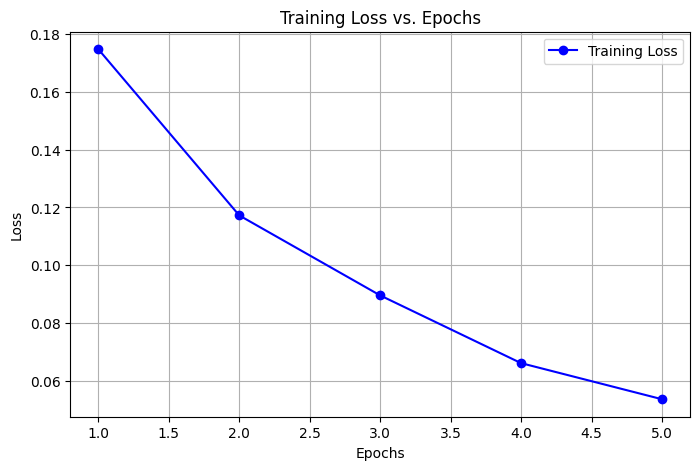

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', color='b', label='Training Loss')
plt.title('Training Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

### ۶. ارزیابی مدل بر روی داده‌های تست
حال عملکرد مدل را روی تصاویر تست ارزیابی کرده و معیارهای Accuracy، Precision، Recall، F1-Score و ماتریس ابهام را محاسبه می‌کنیم.

Test Accuracy:  0.8368
Test Precision: 0.8474
Test Recall:    0.8259
Test F1-score:  0.8365
Test MSE:       0.1348


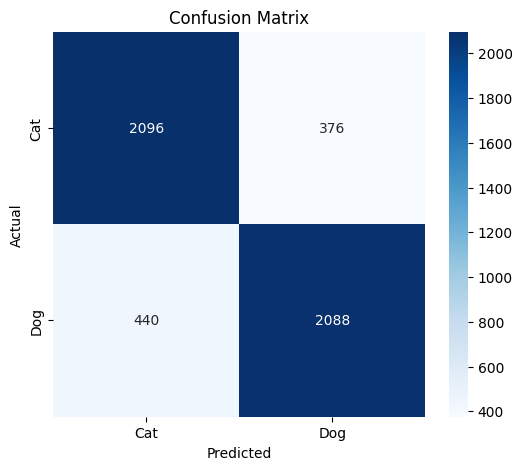

In [9]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, mean_squared_error
import seaborn as sns

model.eval() # قرار دادن مدل در حالت ارزیابی

all_preds = []
all_targets = []
all_outputs_prob = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)

        # گرفتن اندیس کلاس با بیشترین احتمال
        _, preds = torch.max(outputs, 1)

        # اعمال Softmax برای گرفتن احتمالات جهت محاسبات احتمالی دیگر
        probs = F.softmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

        # برای محاسبه تقریب MSE کلاس‌ها، احتمال کلاس ۱ (Dog) را ذخیره می‌کنیم
        all_outputs_prob.extend(probs[:, 1].cpu().numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_outputs_prob = np.array(all_outputs_prob)

# محاسبه شاخص‌های ارزیابی
accuracy = accuracy_score(all_targets, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='binary')
mse = mean_squared_error(all_targets, all_outputs_prob)

print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")
print(f"Test MSE:       {mse:.4f}")

# رسم ماتریس ابهام
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=full_dataset.classes, yticklabels=full_dataset.classes)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

### ۵. رسم نمودار میزان خطا (Loss Curve)
در این بخش نمودار تغییرات خطا را در طول ۵ دوره آموزش رسم می‌کنیم.

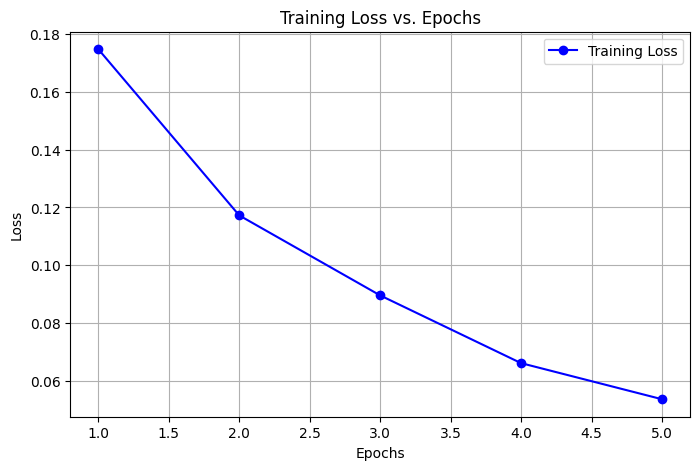

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', color='b', label='Training Loss')
plt.title('Training Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

### ۶. ارزیابی مدل بر روی داده‌های تست
حال عملکرد مدل را روی تصاویر تست ارزیابی کرده و معیارهای Accuracy، Precision، Recall، F1-Score و ماتریس ابهام را محاسبه می‌کنیم.

Test Accuracy:  0.8368
Test Precision: 0.8474
Test Recall:    0.8259
Test F1-score:  0.8365
Test MSE:       0.1348


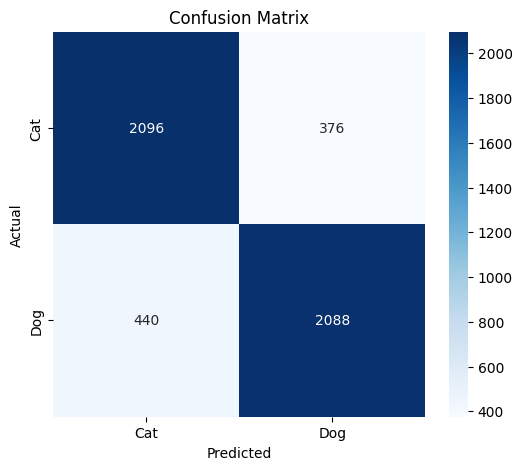

In [11]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, mean_squared_error
import seaborn as sns

model.eval() # قرار دادن مدل در حالت ارزیابی

all_preds = []
all_targets = []
all_outputs_prob = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)

        # گرفتن اندیس کلاس با بیشترین احتمال
        _, preds = torch.max(outputs, 1)

        # اعمال Softmax برای گرفتن احتمالات جهت محاسبات احتمالی دیگر
        probs = F.softmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

        # برای محاسبه تقریب MSE کلاس‌ها، احتمال کلاس ۱ (Dog) را ذخیره می‌کنیم
        all_outputs_prob.extend(probs[:, 1].cpu().numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_outputs_prob = np.array(all_outputs_prob)

# محاسبه شاخص‌های ارزیابی
accuracy = accuracy_score(all_targets, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='binary')
mse = mean_squared_error(all_targets, all_outputs_prob)

print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")
print(f"Test MSE:       {mse:.4f}")

# رسم ماتریس ابهام
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=full_dataset.classes, yticklabels=full_dataset.classes)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

### ۷. بررسی اثر تغییر معماری و تعداد لایه‌ها بر روی عملکرد مدل (Ablation Study)
در این بخش یک معماری متفاوت و ساده‌تر (Shallower CNN) را تعریف می‌کنیم که تنها دارای ۲ لایه کانولوشن است و عملکرد آن را با مدل اول مقایسه می‌کنیم تا متوجه تأثیر تعداد لایه‌ها شویم.

In [12]:
class ShallowCNN(nn.Module):
    def __init__(self):
        super(ShallowCNN, self).__init__()
        # تنها دو لایه کانولوشن به جای سه لایه
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        # پس از ۲ بار پولینگ روی ۱۲۸x۱۲۸، اندازه تصویر ۳۲x۳۲ می‌شود:
        self.fc1 = nn.Linear(32 * 32 * 32, 64)
        self.fc2 = nn.Linear(64, 2)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 32 * 32)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

shallow_model = ShallowCNN().to(device)
print(shallow_model)

ShallowCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=32768, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
)


In [13]:
# تعریف بهینه‌ساز و تابع هزینه برای مدل جدید و آموزش سریع آن در ۳ دوره
shallow_optimizer = optim.Adam(shallow_model.parameters(), lr=0.001)
shallow_losses = []

print("آموزش مدل کم‌عمق (Shallow CNN) به مدت ۳ دوره جهت مقایسه...")
for epoch in range(3):
    shallow_model.train()
    running_loss = 0.0
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs, targets = inputs.to(device), targets.to(device)
        shallow_optimizer.zero_grad()
        outputs = shallow_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        shallow_optimizer.step()
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    shallow_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/3 Completed | Loss: {epoch_loss:.4f}")

آموزش مدل کم‌عمق (Shallow CNN) به مدت ۳ دوره جهت مقایسه...


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 1/3 Completed | Loss: 0.5906
Epoch 2/3 Completed | Loss: 0.4653
Epoch 3/3 Completed | Loss: 0.3840


In [14]:
# ارزیابی سریع مدل کم‌عمق
shallow_model.eval()
shallow_preds = []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = shallow_model(inputs)
        _, preds = torch.max(outputs, 1)
        shallow_preds.extend(preds.cpu().numpy())

shallow_acc = accuracy_score(all_targets, np.array(shallow_preds))
print(f"صحت مدل ۳ لایه اصلی: {accuracy:.4f}")
print(f"صحت مدل ۲ لایه کم‌عمق: {shallow_acc:.4f}")

صحت مدل ۳ لایه اصلی: 0.8368
صحت مدل ۲ لایه کم‌عمق: 0.7806


### ۷. بررسی اثر تغییر معماری و تعداد لایه‌ها بر روی عملکرد مدل (Ablation Study)
در این بخش یک معماری متفاوت و ساده‌تر (Shallower CNN) را تعریف می‌کنیم که تنها دارای ۲ لایه کانولوشن است و عملکرد آن را با مدل اول مقایسه می‌کنیم تا متوجه تأثیر تعداد لایه‌ها شویم.

In [15]:
class ShallowCNN(nn.Module):
    def __init__(self):
        super(ShallowCNN, self).__init__()
        # تنها دو لایه کانولوشن به جای سه لایه
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        # پس از ۲ بار پولینگ روی ۱۲۸x۱۲۸، اندازه تصویر ۳۲x۳۲ می‌شود:
        self.fc1 = nn.Linear(32 * 32 * 32, 64)
        self.fc2 = nn.Linear(64, 2)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 32 * 32)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

shallow_model = ShallowCNN().to(device)
print(shallow_model)

ShallowCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=32768, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
)


In [16]:
# تعریف بهینه‌ساز و تابع هزینه برای مدل جدید و آموزش سریع آن در ۳ دوره
shallow_optimizer = optim.Adam(shallow_model.parameters(), lr=0.001)
shallow_losses = []

print("آموزش مدل کم‌عمق (Shallow CNN) به مدت ۳ دوره جهت مقایسه...")
for epoch in range(3):
    shallow_model.train()
    running_loss = 0.0
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs, targets = inputs.to(device), targets.to(device)
        shallow_optimizer.zero_grad()
        outputs = shallow_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        shallow_optimizer.step()
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    shallow_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/3 Completed | Loss: {epoch_loss:.4f}")

آموزش مدل کم‌عمق (Shallow CNN) به مدت ۳ دوره جهت مقایسه...


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 1/3 Completed | Loss: 0.6337
Epoch 2/3 Completed | Loss: 0.5040
Epoch 3/3 Completed | Loss: 0.4277


In [17]:
# ارزیابی سریع مدل کم‌عمق
shallow_model.eval()
shallow_preds = []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = shallow_model(inputs)
        _, preds = torch.max(outputs, 1)
        shallow_preds.extend(preds.cpu().numpy())

shallow_acc = accuracy_score(all_targets, np.array(shallow_preds))
print(f"صحت مدل ۳ لایه اصلی: {accuracy:.4f}")
print(f"صحت مدل ۲ لایه کم‌عمق: {shallow_acc:.4f}")

صحت مدل ۳ لایه اصلی: 0.8368
صحت مدل ۲ لایه کم‌عمق: 0.7850
